# Lab: Multiple layer Neural Network (MLP) 
This notebook has been prepared by Hsiu-Wen (Kelly) Chang from MINES ParisTech for the class machine learning

## Pytorch 

Pytorch is the most powerful open source deep learning framework. It is a replacement for NumPy (a python library for scientific computing) to use the power of GPUs and other accelerators. Also, the automatic differentiation library is useful to implement neural netorks. In this practical lession, you will first review the use of Numpy to solve a regression problem. Then the use of Pytorch to solve the same problem. Finally, you will practice how to create a complete class to solve a classification problem. 

## Learning objectives
 - Use Numpy to build a simple neural network fit a third order polynomial to sine function and how to replace it with Pytorch
 - Practice the use of neural network from sratch: architecture, activations
 - Practice the use of pytorch module to train an image classifier

**You have four practice questions for your own coding**

## 1. Solving a regression task all by ourself (Numpy): Educational purpose only!
----------------
Let us begin by examining how to solve a regression problem using a polynomial function and the simple gradient descent method to determine the coefficients.   
$$
f(x)=a+bx^{1}+cx^{2}+dx^{3}
$$

In [1]:
%matplotlib inline

99 2172.312289528654
299 1142.6579887264543
499 603.1477696472957
699 320.2221396883482
899 171.72736495060366
1099 93.71834463084691
1299 52.69763205685834
1499 31.104400941149848
1699 19.724964944029587
1899 13.720887527756938
Result: y = -0.03919336925780932 + 0.7889898094481265 x + 0.0066255853561059215 x^2 + -0.08365579700149058 x^3
Train RMSE error: 0.007431896215394668.   Test RMSE error:0.007822753448933796


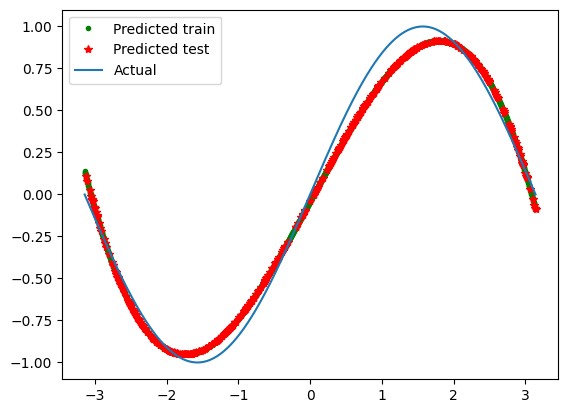

In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt
import time

# Create random input and output data
x_true = np.linspace(-math.pi, math.pi, 2000)
y_true = np.sin(x_true)

# Split data into 80% train and 20% test
mask = np.random.randn(len(x_true)) < 0.8
x_train, y_train = x_true[mask], y_true[mask]
x_val, y_val = x_true[~mask], y_true[~mask]

# Randomly initialize weights
a = np.random.randn()
b = np.random.randn()
c = np.random.randn()
d = np.random.randn()

# Hyperparameters
learning_rate = 1e-6
epochs = 2000

for t in range(epochs):
    # Forward pass: compute predicted y
    # y = a + b x + c x^2 + d x^3``
    y_pred = a + b * x_train + c * x_train ** 2 + d * x_train ** 3

    # Compute and print loss
    loss = np.square(y_pred - y_train).sum()
    if t % 200 == 99:
        print(t, loss)

    # Backprop to compute gradients of a, b, c, d with respect to loss
    grad_y_pred = 2*(y_pred - y_train)
    grad_a = grad_y_pred.sum()
    grad_b = (grad_y_pred * x_train).sum()
    grad_c = (grad_y_pred * x_train ** 2).sum()
    grad_d = (grad_y_pred * x_train ** 3).sum()

    # Update weights
    a -= learning_rate * grad_a
    b -= learning_rate * grad_b
    c -= learning_rate * grad_c
    d -= learning_rate * grad_d

# Print final result
y_pred = a + b * x_train + c * x_train ** 2 + d * x_train ** 3
train_loss=np.square(y_pred - y_train).sum()/y_train.shape[0]
print(f'Result: y = {a} + {b} x + {c} x^2 + {d} x^3')
y_pred_val = a + b * x_val + c * x_val ** 2 + d * x_val ** 3
test_loss = np.square(y_pred_val - y_val).sum()/y_val.shape[0]

print(f'Train RMSE error: {train_loss}.   Test RMSE error:{test_loss}')

plt.plot(x_train, y_pred, 'g.',label='Predicted train')
plt.plot(x_val, y_pred_val, 'r*', label='Predicted test')
plt.plot(x_true,y_true,label='Actual')
plt.legend()
plt.show()

## 1.2 Tensor and autograd 
As this simple code demonstrates, we have to calculate the gradients and update the weights manually; we will now learn how to use PyTorch and a GPU to accelerate this computation process.

- `tensor` is an n-dimensional array that can keep track of a computational graph and gradients, which is important for deep learning. When ``x.requires_grad`` is true, PyTorch's autograd will track its gradients during forward pass. 
- `autograd` is a package that define a compuational graph while execute forward pass of a NN. Nodes in the graphe will be tensors and functions will be edges. Backprogating through this graph then allows us to easily compute gradients 

You should be cautious about ``requires_grad`` because you don't need it on when it is during test mode. And a common error is caused by not reset gradient after the weight update.

In [3]:
import torch
dtype = torch.float
device = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# move input and output to the device
x = torch.tensor(x_train, device=device, dtype=dtype)
y = torch.tensor(y_train, device=device, dtype=dtype)

# Randomly initialize weights and requires the tracking of gradients
a = torch.randn((), dtype=dtype, requires_grad=True)
b = torch.randn((), dtype=dtype, requires_grad=True)
c = torch.randn((), dtype=dtype, requires_grad=True)
d = torch.randn((), dtype=dtype, requires_grad=True)

learning_rate = 1e-6
for t in range(2000):
    # Forward pass: compute predicted y
    y_pred = a + b * x + c * x ** 2 + d * x ** 3

    # Compute and print loss
    loss = (y_pred - y).pow(2).sum()
    if t % 200 == 99:
        print(t, loss.item())

    #use autograd to compute backward pass
    loss.backward()

    # Manually update weights using gradient descent. Wrap in torch.no_grad()
    # because weights have requires_grad=True, but we don't need to track this
    # in autograd.
    with torch.no_grad():
        a -= learning_rate * a.grad
        b -= learning_rate * b.grad
        c -= learning_rate * c.grad
        d -= learning_rate * d.grad

        # Manually zero the gradients after updating weights
        a.grad = None
        b.grad = None
        c.grad = None
        d.grad = None

# Final prediction and plotting
y_pred = a + b * x + c * x ** 2 + d * x ** 3
print(f'Result: y = {a.item()} + {b.item()} x + {c.item()} x^2 + {d.item()} x^3')


Using device: mps
99 4980.7041015625
299 2776.40673828125
499 1551.792724609375
699 870.150146484375
899 490.054931640625
1099 277.74517822265625
1299 158.96263122558594
1499 92.403564453125
1699 55.053367614746094
1899 34.06501007080078
Result: y = 0.154587522149086 + 0.7963070273399353 x + -0.02676132507622242 x^2 + -0.08475936949253082 x^3


## 1.3 nn and optim from PyTorch

Now, let us move on to a modern method for accomplishing this simple task using PyTorch. 

 - ``nn`` module

Computational graphs for deeper networks need a high level of abstraction: layers. The ``nn`` package defines a set of Modules that are roughly equivalent to neural network layers. Each module receives input Tensors and computes output Tensors, and also holds internal state, such as Tensors containing learnable parameters. In addition, the nn package defines a set of useful loss functions that we can use directly. Another important note is the use of ``model.train()`` and ``model.eval()``. Some modules, like Dropout and BatchNorm, behave differently during training and testing; we can use these functions to run the built-in modules properly. See this [document](https://docs.pytorch.org/docs/stable/notes/autograd.html#locally-disable-grad-doc) for more details. In our simple model, this won't change the result yet. 

 - ``optim``

We can see that updating the weights of our models by manually mutating the tensors holding learnable parameters (some might not be learnable when we do transfer learning) with torch.no_grad(). The ``optim`` package provides us modern optimization algorithms such as AdaGrad, RMSProp, and Adam. Here we demonstrate the RMSprop algorithm. 

To further refine our code, we will start using the fit function, which includes the training procedure. This function reduces the need for repeated code in training. This is useful when you fine-tune hyperparameters.

In [4]:
# continaul with the same example
# prepare input features
x_features = torch.stack((x, x**2, x**3), dim=1)  # shape (, 3)

#define model, by default, the newly-created module lives on CPU. It is needed to make sure the all the tensors and modules are on the same device
model = torch.nn.Sequential(
    torch.nn.Linear(3, 1),
    torch.nn.Flatten(0,1) # it flatterns the output of the linear layer to 1D tensor to match the shape of y
)
model.to(device) #move all the parameters to the device

#define loss function: we use mean squared error for regression
loss_fn = torch.nn.MSELoss(reduction='sum')

# define optimizer: we use RMSprop
optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)

def fit(model, loss_fn, optimizer, x_features, y, epochs=2000):
    for t in range(epochs):
        # Forward pass: compute predicted y
        y_pred = model(x_features)  # shape (2000,)

        # Compute and print loss
        loss = loss_fn(y_pred, y)
        if t % 200 == 99:
            print(t, loss.item())

        # Zero gradients, perform a backward pass, and update the weights.
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

model.train()
fit(model, loss_fn, optimizer, x_features, y)

linear_layer=model[0]
print(f'Result: y = {linear_layer.bias.item()} + {linear_layer.weight[:, 0].item()} x + {linear_layer.weight[:, 1].item()} x^2 + {linear_layer.weight[:, 2].item()} x^3')

99 6985.5927734375
299 1094.650146484375
499 779.3092041015625
699 594.533203125
899 385.876953125
1099 216.96859741210938
1299 101.62907409667969
1499 36.32520294189453
1699 11.003639221191406
1899 7.094825744628906
Result: y = 9.899958968162537e-07 + 0.8556529879570007 x + 0.0002495869412086904 x^2 + -0.09258566051721573 x^3


In [15]:
x_val = torch.tensor(x_val, device=device, dtype=dtype)
y_val = torch.tensor(y_val, device=device, dtype=dtype)

model.eval()
pred_val = model(torch.stack((x_val, x_val**2, x_val**3), dim=1))
print(f'Validation loss:{loss_fn(pred_val,y_val).item()}')

Validation loss:1.8680651187896729


/var/folders/8y/hy_g72qn2tj6d0w7ns9q02b00000gn/T/ipykernel_44892/2539830251.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_val = torch.tensor(x_val, device=device, dtype=dtype)
/var/folders/8y/hy_g72qn2tj6d0w7ns9q02b00000gn/T/ipykernel_44892/2539830251.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_val = torch.tensor(y_val, device=device, dtype=dtype)


In [ ]:
# Cell from Ziad

import torch 
dtype = torch.float
device = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda:0" if torch.cuda.is_available() else "cpu")

x = torch.tensor(x_train , device=device, dtype=dtype)
y = torch.tensor(y_train, device=device, dtype=dtype)

#initialize weights
a = torch.randn((), device = device, dtype=dtype, requires_grad=True ) 
b = torch.randn((), device = device, dtype=dtype , requires_grad=True )
c = torch.randn((), device = device, dtype=dtype , requires_grad=True )
d = torch.randn((), device = device, dtype=dtype , requires_grad=True )

epochs = 200
nu = 1e-6

for t in range(epochs) : 
    y_pred = a + b*x + c*torch.pow(x,2)+ d*torch.pow(x,3)

    loss = torch.sum(torch.pow((y_pred - y), 2))

    loss.backward()

    with torch.no_grad() : 
        a -= nu*a.grad
        b -= nu*b.grad
        c -= nu*c.grad
        d -= nu*d.grad

        a.grad = None
        b.grad = None
        c.grad = None
        d.grad = None


    if t%10  == 0 : 
        print(t, loss.item())

print(loss.item())
print(y_pred)





0 64532.01953125
10 3690.64306640625
20 3061.846923828125
30 2830.27734375
40 2706.855712890625
50 2614.268798828125
60 2531.767822265625
70 2453.742919921875
80 2378.6376953125
90 2305.983154296875
100 2235.60107421875
110 2167.39453125
120 2101.2890625
130 2037.21728515625
140 1975.1163330078125
150 1914.9246826171875
160 1856.5836181640625
170 1800.035888671875
180 1745.225830078125
190 1692.10009765625
1645.683837890625
tensor([-0.5284, -0.5264, -0.5245,  ...,  1.8441,  1.8524,  1.8691],
       device='mps:0', grad_fn=<AddBackward0>)


 - Wrape all you need to a class

In deep learning, it is important to test several models with different hyperparameter settings. Here is how we can wrap what we need to a class.

In [ ]:
class mlpregression(torch.nn.Module):
    
    def __init__(self):
        super().__init__()
        self.lc= torch.nn.Linear(3, 1)
        self.fc= torch.nn.Flatten(0,1) 

    def forward(self, x):
        x = self.lc(x)
        y = self.fc(x)
        return y  
    

$\textbf{Practice 1}$: use this class to redo the training of the regression task. Overall, you should have the flowchat of the algorithm like this
1. initialization
2. forward
3. loss
4. Backward
5. optimize
6. print the test loss

In [ ]:

# initialization
mymodel=mlpregression().to(device)

#define loss function: we use mean squared error for regression
loss_fn = torch.nn.MSELoss(reduction='sum')

# define optimizer: we use RMSprop
optimizer = torch.optim.RMSprop(mymodel.parameters(), lr=1e-3)

#training
mymodel.train()
fit(mymodel, loss_fn, optimizer, x_features, y)

model.eval()
pred_val = model(torch.stack((x_val, x_val**2, x_val**3), dim=1))
print(f'Validation loss:{loss_fn(pred_val,y_val).item()}')

99 10524.8916015625
299 1222.454833984375
499 419.8634033203125
699 305.63165283203125
899 173.54800415039062
1099 75.66259765625
1299 24.212787628173828
1499 8.345895767211914
1699 7.0708513259887695
1899 7.046013832092285
Validation loss:1.8680651187896729


In [21]:
x_features = torch.stack((x, x**2, x**3), dim=1)   # shape (N, 3)

model = mlpregression().to(device)

loss_fn = torch.nn.MSELoss(reduction='sum')

optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-3)

#training 


model.train()



def fit(model, loss_fn , optimizer, x,y ) : 
    for t in range(epochs): 
        y_pred = model(x)
        loss = loss_fn(y_pred, y)

        # Zero gradients, perform a backward pass, and update the weights.
        optimizer.zero_grad()
        
        loss.backward()

        optimizer.step()


fit(model, loss_fn, optimizer, x_features, y)

## 2. Pytorch on classifiction with hand-drawn digits images
----------------

We are going to targeting the application of predicting the hand-drawn digits (between 0 and 9) in a given black-and-white image. First, we will see how to preprocess the data and eventually use the public dataset provided by ```torchvision```. 

### 2.1 download raw images by URL. 
![](http://perso.mines-paristech.fr/fabien.moutarde/ES_MachineLearning/TP_convNets/mnist.png)  
You can use [pathlib](https://docs.python.org/3/library/pathlib.html)
for dealing with paths (part of the Python 3 standard library), and download the dataset using
[requests](http://docs.python-requests.org/en/master/). We will only import modules when we use them, so you can see exactly what's being used at each point.


In [22]:
from pathlib import Path
import requests

DATA_PATH = Path("data")
PATH = DATA_PATH / "mnist"

PATH.mkdir(parents=True, exist_ok=True)

URL = "https://github.com/pytorch/tutorials/raw/main/_static/"
FILENAME = "mnist.pkl.gz"

if not (PATH / FILENAME).exists():
        content = requests.get(URL + FILENAME).content
        (PATH / FILENAME).open("wb").write(content)

In [23]:
import os
print(os.getcwd())
print((PATH / FILENAME))

/Users/ziadbalbzioui/Downloads/TP_introML/work
data/mnist/mnist.pkl.gz


This dataset is in numpy array format, and has been stored using pickle, a python-specific format for serializing data. Each image is 28x28 pixels, and is being stored as a flattened rwo of length 784. To have a look at one provided image, we need to reshape it to 2D. In addition, PyTorch uses ``torch.tensor``, rather than numpy arrays, so we need to convert our data.

size of training data (number of samples, number of pixels): (50000, 784)
size of test data (number of samples, number of pixels): (10000, 784)


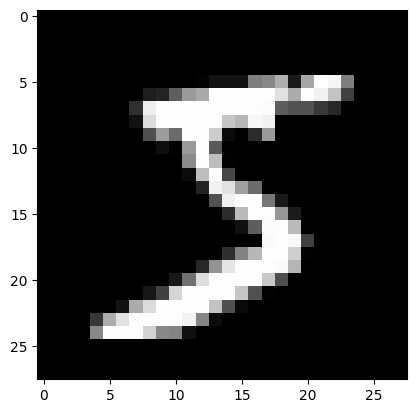

In [24]:
import pickle
import gzip

with gzip.open((PATH / FILENAME).as_posix(), "rb") as f:
        ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding="latin-1")

plt.imshow(x_train[0].reshape(28,28), cmap='gray')
print(f"size of training data (number of samples, number of pixels): {x_train.shape}")
print(f"size of test data (number of samples, number of pixels): {x_valid.shape}")

# Convert data to torch tensors and move to detected device
x_train, y_train, x_valid, y_valid = map(
    lambda x: torch.tensor(x).to(device), (x_train, y_train, x_valid, y_valid)
)

## 2.2 Without nn modules

In [25]:
# Create a NN with linear model and (28*28) inputs and 10 outputs

# Initialize weights and bias 
weights = torch.randn(28*28, 10, device=device, dtype=dtype, requires_grad=True)
bias = torch.randn(10, device=device, dtype=dtype, requires_grad=True)

Pytorch has several built-in activation functions in ```torch.nn.functional```, however, it is necessary to know how to define one by yourself. PyTorch will
even create fast GPU or vectorized CPU code for your function automatically. Let's define log_softmax function and use it as our activation to increase the complexity of our NN

$${\bf \theta} = \log\left(\frac{{\exp}({x_{i})}}{\sum_{j}{\bf \exp}({x_{j})}}\right)$$
$${\bf \theta} = x-\log{\sum_{j}{\bf \exp}({x_{j})}}$$

In [26]:
def log_softmax(x):
    # Implement log_softmax function
    return x - torch.logsumexp(x, dim=1, keepdim=True)

def model(x):
    # Implement the NN model
    return log_softmax(x.mm(weights) + bias)

In the above, the ``@`` stands for the dot product operation.

Now we design a batch size of 64 to train each time

In [27]:
bs = 64  # batch size

xb = x_train[0:bs]  # a mini-batch from x without randomness

preds = model(xb)  # predictions with initial model

print(preds[0], preds.shape)

tensor([ -1.5087,  -0.3869,  -4.0197, -20.5509,  -5.3149, -17.2104,  -9.4261,
         -2.6034,  -5.9508, -10.4623], device='mps:0',
       grad_fn=<SelectBackward0>) torch.Size([64, 10])


As you see, the ``preds`` tensor contains not only the tensor values, but also a
gradient function. We'll use this later to do backprop.

Let's implement negative log-likelihood to use as the loss function
(again, we can just use standard Python):



In [28]:
def nll(input, target):
    return -input[range(target.shape[0]), target].mean()

loss_func = nll

Let's check our loss with our random model, so we can see if we improve
after a backprop pass later.



In [29]:
yb = y_train[0:bs]
print(preds[range(yb.shape[0]),yb])
print(f'Current loss:{loss_func(preds, yb).item()}')

tensor([-1.7210e+01, -1.4476e+01, -2.4140e-02, -9.2132e+00, -1.1163e+01,
        -8.1253e-02, -1.0369e+01, -1.7827e+01, -5.3994e+00, -1.2218e+01,
        -1.9553e+01, -2.5596e+01, -3.0876e+00, -3.3950e+01, -1.1883e+01,
        -1.3074e+01, -6.1787e+00, -1.0904e+01, -1.3222e+01, -2.0277e+00,
        -4.1225e+00, -1.2875e+01, -5.1012e+00, -9.6640e+00, -6.7134e+00,
        -1.1444e-05, -1.4439e-03, -1.9065e+01, -1.4817e+01, -2.4217e+01,
        -1.8765e+01, -2.6386e+01, -2.0446e+01, -4.3814e+00, -8.4594e+00,
        -1.3611e+01, -2.5943e+01, -1.3170e+01, -1.4871e+01, -2.2613e+01,
        -1.0532e+01, -1.9575e+01, -4.3816e+00, -1.2875e+01, -8.0711e+00,
        -1.9383e+01, -2.5631e+01, -1.4943e+01, -1.5905e+01, -2.2253e+01,
        -1.3680e+01, -6.3264e+00, -2.6028e+01, -8.7126e+00, -2.3355e+01,
        -7.9275e+00, -2.1769e+01, -1.3411e+01, -1.0092e+01, -1.8519e+01,
        -1.4786e+01, -9.3568e+00, -2.0564e+01, -1.9683e+01], device='mps:0',
       grad_fn=<IndexBackward0>)
Current loss:1

Let's also implement a function to calculate the accuracy of our model.
For each prediction, if the index with the largest value matches the
target value, then the prediction was correct.



In [30]:
def accuracy(out, yb):
    preds = torch.argmax(out, dim=1)
    return (preds == yb).float().mean()

Let's check the accuracy of our random model, so we can see if our
accuracy improves as our loss improves.



In [31]:
print(accuracy(preds, yb))

tensor(0.0625, device='mps:0')


We can now run a training loop.  For each iteration, we will:

- select a mini-batch of data (of size ``bs``)
- use the model to make predictions
- calculate the loss
- ``loss.backward()`` updates the gradients of the model, in this case, ``weights``
  and ``bias``.

In [32]:
lr = 0.5  # learning rate
epochs = 2  # how many epochs to train for

for epoch in range(epochs):
    for i in range((x_train.shape[0] - 1) // bs + 1): #floor division
        start_i=i*bs
        end_i =start_i + bs
        # grab batch of data (xb) and targets (yb)
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]
        # predict output
        preds = model(xb)
    
        # calculate loss
        loss = loss_func(preds, yb)

        # backpropagation error
        loss.backward()
        with torch.no_grad():
            #update weights and bias
            weights -= weights.grad * lr
            bias -= bias.grad * lr
            # zero the gradients
            weights.grad.zero_()
            bias.grad.zero_()

    print('Epochs {}: loss {}, accuracy {}'.format(epoch, loss_func(model(xb), yb), accuracy(model(xb), yb)))

Epochs 0: loss 0.2696141302585602, accuracy 0.9375
Epochs 1: loss 0.15107795596122742, accuracy 0.9375


That's it: we've created and trained a minimal neural network (in this case, a
logistic regression, since we have no hidden layers) entirely from scratch!

Let's check the loss and accuracy and compare those to what we got
earlier. We expect that the loss will have decreased and accuracy to
have increased, and they have.



In [33]:
print('loss:', loss_func(model(xb), yb).item(), 'accuracy:', accuracy(model(xb), yb).item())

loss: 0.15107795596122742 accuracy: 0.9375


### 2.3 Using PyTorch modules for training, testing and validation


The above work can be easily done by using torch.nn. Here is how we can code it in a pretty way. 

Here is the list of modules that you should try to use:
1. [torch.nn](https://pytorch.org/docs/stable/nn.html): Linear, CrossEntropyLoss, functional.log_softmax
2. [torch.optim](https://pytorch.org/docs/stable/optim.html): SGD
3. [Dataset](https://pytorch.org/docs/stable/data.html?highlight=dataset#torch.utils.data.Dataset)
4. [DataLoader](https://pytorch.org/docs/stable/data.html?highlight=dataloader#torch.utils.data.DataLoader)

In [34]:
import torch.nn.functional as F
import torch.nn as nn
import torch.optim as optim

# Step 1: use activation and loss function from ``torch.nn.functional``. We use torch.nn.Parameter for defining learnable parameters of a model. They can be returned by Minist_Logistic.parameters()
# Define your model using nn.Module
class Mnist_Logistic(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28*28, 10) #linear layer

    def forward(self, x):
        
        return F.log_softmax(self.fc1(x), dim=1) 

# Intialize the model and move it to the device
model = Mnist_Logistic().to(device)
print(model)
# see the size of learnable parameters
params=list(model.parameters())
print(params[0].shape)  # weights
print(params[1].shape)  # bias

# Step 2: Define a loss function and an optimizer
criterion = torch.nn.CrossEntropyLoss()
out=model(x_train[0].unsqueeze(0))  # unsqueeze to add batch dimension
print(f'Dimenstion of output tensor:{out.shape}')
loss=criterion(out, y_train[0].unsqueeze(0))

# Step 3: Define a optimizer that uses stochastic gradient descent to update trainable parameters
optimizer = optim.SGD(model.parameters(), lr=0.1)


Mnist_Logistic(
  (fc1): Linear(in_features=784, out_features=10, bias=True)
)
torch.Size([10, 784])
torch.Size([10])
Dimenstion of output tensor:torch.Size([1, 10])


In [35]:
print(loss)
# For illustration, let us follow a few steps backward
print(loss.grad_fn)  # NLLLoss
print(loss.grad_fn.next_functions[0][0])  # LogSoftmax

model.zero_grad()
print('fc1 weight grad before backward:', model.fc1.weight.grad)

loss.backward()
print('fc1 weight grad after backward:', model.fc1.weight.grad)

tensor(2.2579, device='mps:0', grad_fn=<NllLossBackward0>)
fc1 weight grad before backward: None
fc1 weight grad after backward: tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]], device='mps:0')


In [39]:
def fit(model, loss_func, optimizer, x_train, y_train, bs, epochs=5, lr=0.1):
    for epoch in range(epochs):
        for i in range((x_train.shape[0] - 1) // bs + 1): #floor division
            start_i=i*bs
            end_i =start_i + bs
            # grab batch of data (xb) and targets (yb)
            xb = x_train[start_i:end_i]
            yb = y_train[start_i:end_i]
            # predict output
            preds = model(xb)
        
            # calculate loss
            loss = loss_func(preds, yb)

            # backpropagation error and update weights
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        print('Epochs {}: loss {}, accuracy {}'.format(epoch, loss_func(model(x_valid), y_valid), accuracy(model(x_valid), y_valid)))

Instantiate your function and check loss value



In [40]:
fit(model, criterion, optimizer, x_train, y_train, bs,epochs=5, lr=0.01)

Epochs 0: loss 0.26868125796318054, accuracy 0.9251000285148621
Epochs 1: loss 0.26759710907936096, accuracy 0.9258000254631042
Epochs 2: loss 0.2666652202606201, accuracy 0.9261000156402588
Epochs 3: loss 0.26585689187049866, accuracy 0.9265000224113464
Epochs 4: loss 0.2651502788066864, accuracy 0.9269999861717224


$\textbf{Practice 2}$: Add one more layer to improve the accuracy

In [43]:
## TODO 


class Mnist_MLP(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(28*28,28*28 ) #linear layer
        self.fc2 = nn.Linear(28*28, 10 )

    def forward(self, x):
        return F.log_softmax(self.fc2(F.relu(self.fc1(x))), dim=1) 


modelMLP = Mnist_MLP().to(device)
params=list(modelMLP.parameters())
optimizer = optim.SGD(modelMLP.parameters(), lr=0.1)

fit(modelMLP, criterion, optimizer, x_train, y_train, bs,epochs=5, lr=0.01)



Epochs 0: loss 0.2695285379886627, accuracy 0.9240000247955322
Epochs 1: loss 0.18927448987960815, accuracy 0.9496999979019165
Epochs 2: loss 0.1490778625011444, accuracy 0.960099995136261
Epochs 3: loss 0.12625987827777863, accuracy 0.9659000039100647
Epochs 4: loss 0.11185739934444427, accuracy 0.9700000286102295


Until now, we can see we are not smart in picking a batch of input. It is better to you TensorDataset tools that provide us the randonness and split function to deal with data sampling. 

PyTorch has an abstract Dataset class. A Dataset can be anything that has a __len__ function (called by Python's standard len function) and a __getitem__ function as a way of indexing into it. This [tutorial](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) walks through a nice example of creating a custom FacialLandmarkDataset class as a subclass of Dataset.

By defining a length and way of indexing, this also gives us a way to iterate, index, and slice along the first dimension of a tensor. This will make it easier to access both the independent and dependent variables in the same line as we train.

In [ ]:
from torch.utils.data import TensorDataset
train_ds = TensorDataset(x_train, y_train)

# This is how to get a batch of data from the TensorDataset
xb, yb = train_ds[0:bs]

print(xb.shape, yb.shape)


- using DataLoader

Pytorch's ``DataLoader`` is responsible for managing batches. You can
create a ``DataLoader`` from any ``Dataset``. ``DataLoader`` makes it easier
to iterate over batches. Rather than having to use ``train_ds[i*bs : i*bs+bs]``,
the DataLoader gives us each minibatch automatically.



In [ ]:
from torch.utils.data import DataLoader

train_dl = DataLoader(train_ds, batch_size=bs)

In [ ]:
# use the DataLoader to get a batch of data
xb, yb = next(iter(train_dl)) 
print(xb.shape, yb.shape)

Thanks to Pytorch's ``nn.Module``, ``nn.Parameter``, ``Dataset``, and ``DataLoader``,
our training loop is now dramatically smaller and easier to understand. Let's
now try to add the basic features necessary to create effecive models in practice.

 -  Add validation
In reality, we always need to take care the overfitting issue. We can avoid it by:
(1) add validation
(2) shuffling the training data prevent correlation between batches and overfitting. 

In [ ]:
train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True)

valid_ds = TensorDataset(x_valid, y_valid)
valid_dl = DataLoader(valid_ds, batch_size=bs * 2)

(Note that we always call ``model.train()`` before training, and ``model.eval()``
before inference, because these are used by layers such as ``nn.BatchNorm2d``
and ``nn.Dropout`` to ensure appropriate behaviour for these different phases.)

$\textbf{Practice 3}$: rewrite the fit function with train_dl and valid_dl and save the loss and accuracy for each epoch in order to to practice 4.

In [ ]:
# TODO


$\textbf{Practice 4}$: plot loss values and validations values
In order to understand the progress of your training, error curves with test and validation are very common to be shown.
Change your code in order to see the curves

In [ ]:
# TODO

Summary 
-----------------

We have seen and practice the following functions

 - **torch.nn**

   + ``Module``: creates a callable which behaves like a function, but can also
     contain state(such as neural net layer weights). It knows what ``Parameter`` (s) it
     contains and can zero all their gradients, loop through them for weight updates, etc.
   + ``Parameter``: a wrapper for a tensor that tells a ``Module`` that it has weights
     that need updating during backprop. Only tensors with the `requires_grad` attribute set are updated
   + ``functional``: a module(usually imported into the ``F`` namespace by convention)
     which contains activation functions, loss functions, etc, as well as non-stateful
     versions of layers such as convolutional and linear layers.
 - ``torch.optim``: Contains optimizers such as ``SGD``, which update the weights
   of ``Parameter`` during the backward step
 - ``Dataset``: An abstract interface of objects with a ``__len__`` and a ``__getitem__``,
   including classes provided with Pytorch such as ``TensorDataset``
 - ``DataLoader``: Takes any ``Dataset`` and creates an iterator which returns batches of data.

